# 04 · Simulación: de una capa de HMI a un campo 3D con $\nabla\cdot\mathbf B=0$ y a $Z_W$ (S2, S5, S6)

HMI da $\mathbf B=(B_x,B_y,B_z)$ en **una** capa. La integral de curvatura del balance horizontal (S1),

$$C=\frac{1}{\mu_0}\int_0^\infty B_z\,\frac{\partial B_r}{\partial z}\,dr ,\qquad p_{ext}=p_{eje}+\frac{B^2}{2\mu_0}+C ,$$

necesita saber cómo cambia el campo con la altura. Este notebook:

1. comprueba el **modelo autosimilar** (S2): $\nabla\cdot\mathbf B=0$, $\tan\gamma=r/2L$ y la fórmula cerrada de $C$;
2. **extiende a 3D** un mapa de una capa de varias maneras y muestra qué fija cada una;
3. **ajusta** $B_0$, $R$ y $L$ a un mapa (perfiles de S4);
4. pasa a $Z_W$ con presión sola y con presión + curvatura (S5);
5. hace la **calibración** de $n$ con la tabla de Löptien (S6), por ahora solo con lo que no depende de los datos;
6. corre todo sobre los **datos reales** de `data/processed/` si ya están en disco.

Las secciones 1–5 usan una mancha sintética, así que corren sin datos. Código: `src/autosimilar.py`, `src/extrapolacion.py`, `src/perfiles.py`, `src/modelo_wilson.py`. Pruebas: `python tests_simulacion/test_simulacion.py`.

Una revisión independiente rehízo las deducciones con sympy y probó el código con otros parámetros; sus hallazgos están incorporados (ver `docs/simulacion.md`, sección 6).

In [1]:
import pathlib, sys, warnings
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import autosimilar as au, extrapolacion as ex, perfiles as pf, modelo_wilson as mw

FIG = ROOT / 'docs' / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})
pd.set_option('display.width', 200); pd.set_option('display.float_format', '{:.4g}'.format)

# Mancha de referencia (parecida a una de HMI): B0 = 2.5 kG, R = 8 Mm, L = 4 Mm, píxel CEA 0.36 Mm
B0, R, L, DX = 2500.0, 8.0, 4.0, 0.36
PM = au.presion_magnetica(B0)
print(f'B0²/2μ0 = {PM:.3g} Pa   (3 kG: {au.presion_magnetica(3000):.3g} Pa)')

B0²/2μ0 = 2.49e+04 Pa   (3 kG: 3.58e+04 Pa)


## 1. Modelo autosimilar (S2)

$$B_z=B_0(z)\,e^{-\zeta^2},\quad \zeta=\frac{r}{R(z)},\quad R(z)=R_0\sqrt{\frac{B_0(0)}{B_0(z)}},\qquad B_r=-\frac r2\frac{dB_0}{dz}\,e^{-\zeta^2}$$

$B_r$ no se escoge: sale de $\frac1r\partial_r(rB_r)+\partial_zB_z=0$. La familia vertical $B_0(z)=B_0\,(1+z/nL)^{-n}$ tiene la misma $B_0$ y la misma $L=-B_0/B_0'$ en $z=0$ para cualquier $n$; solo cambia la **segunda** derivada, que es la que entra en

$$\frac{C}{B_0^2/2\mu_0}=-\left(\frac RL\right)^2\frac{n+2}{8n}.$$

Comprobaciones numéricas que pide S2: divergencia en la malla y fórmula cerrada contra la integral numérica.

In [2]:
r = np.linspace(0.3, 20, 60)
filas = []
for n in (-1, -2, -0.5, 3, np.inf):
    div = max(np.max(np.abs(au.divergencia(r, z, B0, R, L, n))) for z in (-0.5, 0, 0.7))
    filas.append({'n': n, 'max|∇·B| / (B0/L)': div / (B0 / L),
                  'C/Pmag cerrada': au.C(B0, R, L, n) / PM, 'C/Pmag numérica': au.C_numerica(B0, R, L, n) / PM})
pd.DataFrame(filas).set_index('n')

,max|∇·B| / (B0/L),C/Pmag cerrada,C/Pmag numérica
n,,,
-1,2.241e-08,0.5,0.5
-2,2.386e-08,0,6.66e-07
-0.5,7.866e-08,1.5,1.5
3,4.579e-08,-0.8333,-0.8333
inf,3.304e-08,-0.5,-0.5


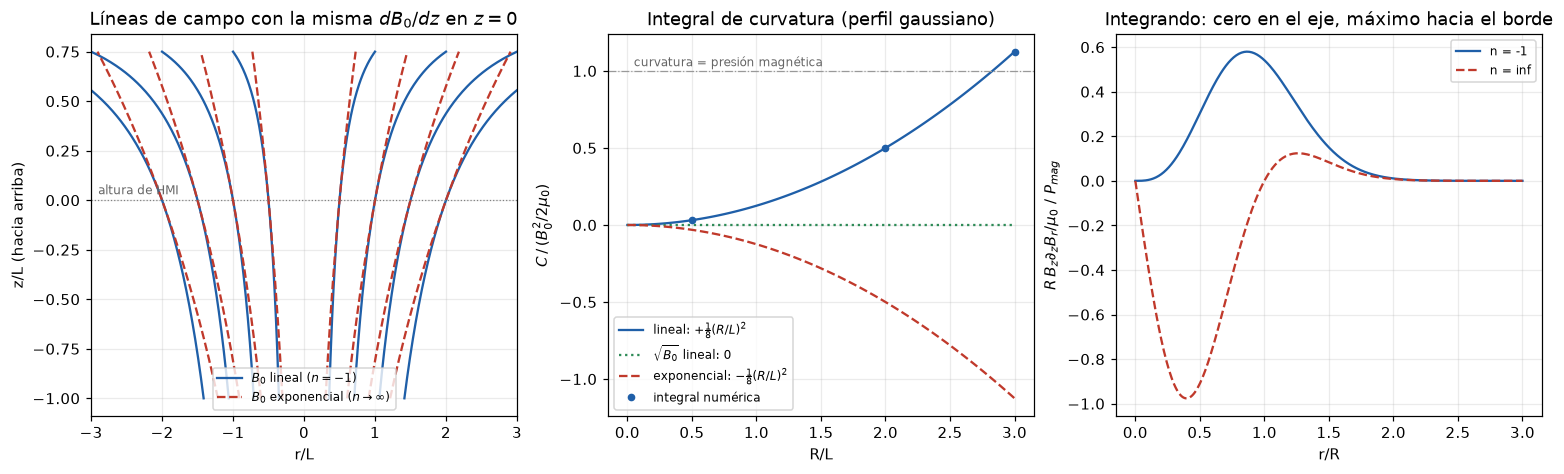

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), layout='constrained')

# (a) líneas de campo: misma B0 y misma dB0/dz en z = 0, distinta curvatura lejos de ahí
z = np.linspace(-1, 0.75, 200) * L
for n, c, ls, lab in ((-1, '#1f5fa8', '-', r'$B_0$ lineal ($n=-1$)'), (np.inf, '#c0392b', '--', r'$B_0$ exponencial ($n\to\infty$)')):
    for i, r0 in enumerate(np.array([0.25, 0.5, 0.75, 1.0]) * R):
        rl = au.lineas_de_campo(r0, z, B0, R, L, n)
        ax[0].plot(rl / L, z / L, c=c, ls=ls, label=lab if i == 0 else None)
        ax[0].plot(-rl / L, z / L, c=c, ls=ls)
ax[0].axhline(0, c='0.5', lw=0.8, ls=':'); ax[0].text(-2.9, 0.03, 'altura de HMI', fontsize=8, c='0.4')
ax[0].set(xlabel='r/L', ylabel='z/L (hacia arriba)', title='Líneas de campo con la misma $dB_0/dz$ en $z=0$', xlim=(-3, 3))
ax[0].legend(fontsize=8, loc='lower center')

# (b) C contra R/L
RL = np.linspace(0, 3, 100)
for n, c, ls in ((-1, '#1f5fa8', '-'), (-2, '#2e8b57', ':'), (np.inf, '#c0392b', '--')):
    lab = {-1: 'lineal: $+\\frac{1}{8}(R/L)^2$', -2: '$\\sqrt{B_0}$ lineal: 0'}.get(n, 'exponencial: $-\\frac{1}{8}(R/L)^2$')
    ax[1].plot(RL, au.factor_curvatura(n) * RL ** 2, c=c, ls=ls, label=lab)
ax[1].plot([0.5, 2, 3], [au.C_numerica(B0, R, R / x, -1) / PM for x in (0.5, 2, 3)], 'o', c='#1f5fa8', ms=4, label='integral numérica')
ax[1].axhline(1, c='0.6', lw=0.8, ls='-.'); ax[1].text(0.05, 1.03, 'curvatura = presión magnética', fontsize=8, c='0.4')
ax[1].set(xlabel='R/L', ylabel='$C\\,/\\,(B_0^2/2\\mu_0)$', title='Integral de curvatura (perfil gaussiano)')
ax[1].legend(fontsize=8)

# (c) dónde se acumula C
rr = np.linspace(0, 3 * R, 300)
for n, c, ls in ((-1, '#1f5fa8', '-'), (np.inf, '#c0392b', '--')):
    ax[2].plot(rr / R, au.integrando_curvatura(rr, B0, R, L, n) * R / PM, c=c, ls=ls, label=f'n = {n}')
ax[2].set(xlabel='r/R', ylabel='$R\\,B_z\\partial_zB_r/\\mu_0$ / $P_{mag}$', title='Integrando: cero en el eje, máximo hacia el borde')
ax[2].legend(fontsize=8)
fig.savefig(FIG / '04_modelo_autosimilar.png', dpi=160); plt.show()

## 2. De una capa a 3D: ¿qué significa "imponer $\nabla\cdot\mathbf B=0$"?

Se parte de un mapa de una capa (aquí, sintético con ruido) y se extiende a un cubo de cinco maneras:

| Método | Qué deja fijo | Qué supone hacia arriba |
|---|---|---|
| **Capas iguales** | todo el mapa | nada cambia con $z$ → $\nabla\cdot\mathbf B=\nabla_h\cdot\mathbf B_h\neq0$ |
| **Capas iguales + Gauss** | todo el mapa | $\mathbf B_h$ no cambia; $B_z(z)=B_z(0)-z\,\nabla_h\cdot\mathbf B_h$ |
| **Proyección de Helmholtz** | nada | la corrección mínima en norma $L_2$ (caja periódica) |
| **Campo potencial** | $B_z$ | no hay corrientes, $\mathbf J=0$ |
| **Autosimilar desde el mapa** | $B_z$ | misma forma a toda altura; $L$ y $n$ |

Para cada cubo se miden la divergencia y cuánto cambió el mapa de $z=0$ (ambos sobre la mancha, $r<1.5R$), $\partial_zB_z$ en el centro, y la integral de curvatura (integrada hasta $r=3R$). Valores de referencia para $\partial_zB_z\,L/B_0$: $-1$ en el modelo autosimilar (cualquier $n$) y $-\sqrt\pi\,L/R=-0.886$ en el potencial.

In [4]:
RUIDO = 30.0   # G por componente
Bx0, By0, Bz0 = ex.mancha_sintetica(B0, R, L, n=-1, nx=201, dx=DX, ruido=RUIDO, semilla=1)
z = np.linspace(0, 1.2, 7)            # Mm
dz = z[1] - z[0]
Xs, Ys = ex.rejilla(Bz0.shape, DX)
SPOT = np.hypot(Xs, Ys) < 1.5 * R                     # las métricas se miden sobre la mancha
norma = lambda a: np.sqrt(np.mean(a[..., SPOT] ** 2))
Bh0 = np.hypot(Bx0, By0)
from scipy.ndimage import gaussian_filter
Bz0_s = gaussian_filter(Bz0, 2.0)                     # el mapa se suaviza (σ = 2 px) antes de reescalarlo

def medir(nombre, Bx, By, Bz, **kw):
    div = ex.divergencia(Bx, By, Bz, DX, z)[1:-1]
    c = ex.integral_curvatura(Bx, By, Bz, DX, z, r_max=3 * R, **kw)[0]
    return {'método': nombre, 'rms ∇·B / (B0/L)': norma(div) / (B0 / L),
            'cambio en B_h(z=0) [rms/rms]': norma(np.hypot(Bx[0] - Bx0, By[0] - By0)) / norma(Bh0),
            'cambio en B_z(z=0) [rms/rms]': norma(Bz[0] - Bz0) / norma(Bz0),
            '∂zBz centro · L/B0': np.mean(((-3 * Bz[0] + 4 * Bz[1] - Bz[2]) / (2 * dz))[98:103, 98:103]) * L / B0,
            'C / Pmag': c / PM}

cubos, filas = {}, []
cubos['capas iguales'] = ex.capas_iguales(Bx0, By0, Bz0, len(z))
bx, by, _ = cubos['capas iguales']
cubos['capas iguales + Gauss'] = (bx, by, ex.integrar_gauss(bx, by, Bz0, DX, z))
cubos['proyección de Helmholtz'] = ex.limpiar_divergencia(*cubos['capas iguales'], DX, dz)
px, py, pz, dpx, dpy = ex.campo_potencial(Bz0, DX, z, relleno=300)
cubos['campo potencial (J = 0)'] = (px, py, pz)
for n in (-1, -2, np.inf):
    cubos[f'autosimilar desde el mapa, n = {n}'] = ex.autosimilar_desde_mapa(Bz0_s, DX, z, L, n)
for nombre, (bx_, by_, bz_) in cubos.items():
    kw = dict(dBx_dz=dpx, dBy_dz=dpy) if 'potencial' in nombre else {}
    filas.append(medir(nombre, bx_, by_, bz_, **kw))
tabla2 = pd.DataFrame(filas).set_index('método')
print(f'Fórmula cerrada: C/Pmag = {au.C(B0, R, L, -1) / PM:+.3f} (n = -1), 0 (n = -2), {au.C(B0, R, L, np.inf) / PM:+.3f} (exp);  potencial: -1')
tabla2

Fórmula cerrada: C/Pmag = +0.500 (n = -1), 0 (n = -2), -0.500 (exp);  potencial: -1


,rms ∇·B / (B0/L),cambio en B_h(z=0) [rms/rms],cambio en B_z(z=0) [rms/rms],∂zBz centro · L/B0,C / Pmag
método,,,,,
capas iguales,0.347,0,0,-3.638e-16,-3.5e-15
capas iguales + Gauss,5.334e-16,0,0,-0.9823,-3.5e-15
proyección de Helmholtz,0.04764,0.9993,4.008e-16,1.455e-16,3.267e-15
campo potencial (J = 0),0.03675,0.2772,2.844e-16,-0.8674,-0.9984
"autosimilar desde el mapa, n = -1",0.0005761,0.05296,0.02791,-0.9702,0.4907
"autosimilar desde el mapa, n = -2",0.0004868,0.05296,0.02791,-0.9702,0.002907
"autosimilar desde el mapa, n = inf",0.0005746,0.05296,0.02791,-0.9694,-0.4864


**Lectura de la tabla.**

- **Capas iguales** no cumple Gauss: la divergencia es del orden de $B_0/L$.
- **Capas iguales + Gauss** sí cumple, respeta el mapa y recupera $\partial_zB_z=-B_0/L$ en el centro. Pero **$C=0$ ahí no es un resultado, es la hipótesis**: se eligió $\partial_z\mathbf B_h=0$ (orden 1 en $B_z$, orden 0 en $\mathbf B_h$). Con una sola capa la ley de Gauss fija $\partial_zB_z$ y nada más. Dicho de forma exacta: $C=-B_0^2/2\mu_0+\int B_zJ_\varphi\,dr$, y lo que una capa no fija es la corriente azimutal $J_\varphi$.
- **La proyección de Helmholtz** da divergencia cero, pero lo logra borrando casi todo $\mathbf B_h$. Pasa porque el cubo de partida no cambia con $z$: solo sobrevive $k_z=0$, la proyección se vuelve 2D, y el campo horizontal de una mancha es casi puramente divergente. Deja $\partial_zB_z\approx0$: destruye la señal que se quería usar. "Imponer divergencia cero" no basta; hay que decir qué se deja fijo. (La divergencia que queda en la tabla para este método y para el potencial es el ruido de 30 G derivado por diferencias finitas; espectralmente es cero.)
- **El campo potencial** respeta $B_z$ pero no tiene corrientes, así que $\mathbf J\times\mathbf B=0$ y $C=-P_{mag}$: la tensión cancela la presión magnética y no quedaría depresión de Wilson magnética. Las manchas reales no son potenciales (tienen la lámina de corriente $J_\varphi$ del borde); sirve como caso límite y como prueba del código.
- **La expansión autosimilar del mapa** respeta $B_z$ (salvo el suavizado previo), cumple Gauss para cualquier forma de la mancha y deja la segunda derivada en un parámetro, $n$. Reproduce la fórmula cerrada dentro del ruido. Su $\mathbf B_h$ en $z=0$ es una predicción, $\mathbf x B_z/2L$; la diferencia con el observado es aquí solo el ruido, y con datos reales es la prueba del modelo (`perfiles.residuo_inclinacion`). La divergencia residual viene de derivar numéricamente un mapa con ruido.

Conclusión para el proyecto: los datos fijan $B_0$, $R$ y $L$; el signo y el tamaño de $C$ dependen de la clausura ($n$), y esa es la que se calibra con Löptien en S6.

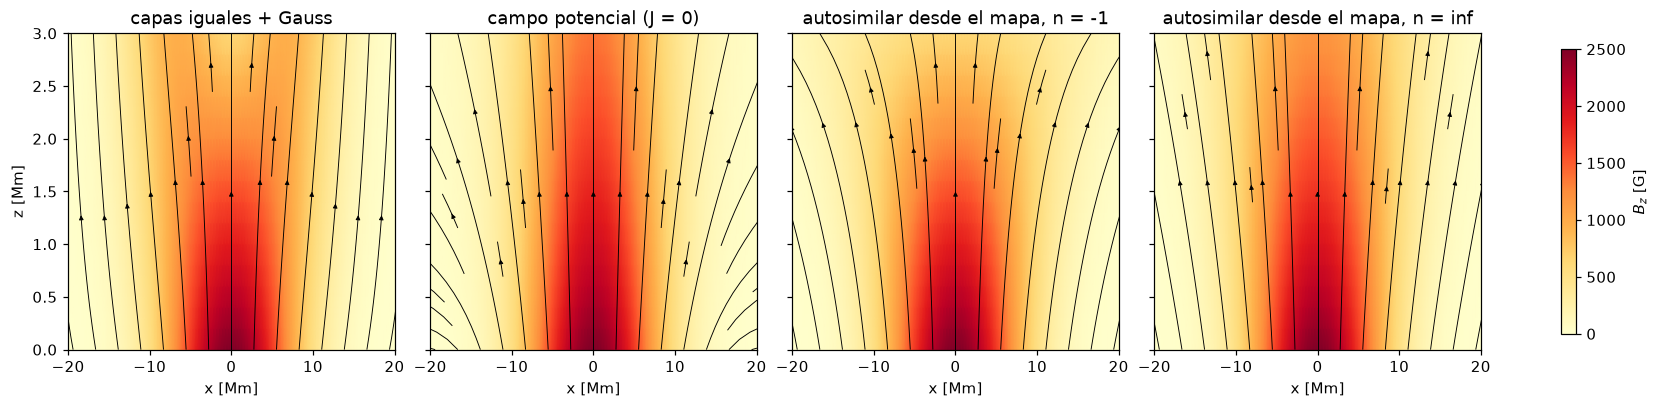

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), layout='constrained', sharey=True)
zz = np.linspace(0, 3, 16)
x = (np.arange(201) - 100) * DX
sel = {'capas iguales + Gauss': None, 'campo potencial (J = 0)': None,
       'autosimilar desde el mapa, n = -1': -1, 'autosimilar desde el mapa, n = inf': np.inf}
_, _, Bz_lim = ex.mancha_sintetica(B0, R, L, n=-1, nx=201, dx=DX)      # sin ruido, para el dibujo
bx_l, by_l, _ = ex.mancha_sintetica(B0, R, L, n=-1, nx=201, dx=DX)
for ax, (nombre, n) in zip(axes, sel.items()):
    if 'Gauss' in nombre:
        cx, cy, _ = ex.capas_iguales(bx_l, by_l, Bz_lim, len(zz)); cz = ex.integrar_gauss(cx, cy, Bz_lim, DX, zz)
    elif 'potencial' in nombre:
        cx, cy, cz, _, _ = ex.campo_potencial(Bz_lim, DX, zz, relleno=300)
    else:
        cx, cy, cz = ex.autosimilar_desde_mapa(Bz_lim, DX, zz, L, n)
    im = ax.pcolormesh(x, zz, cz[:, 100, :], cmap='YlOrRd', vmin=0, vmax=B0, shading='gouraud')
    ax.streamplot(x, zz, cx[:, 100, :], cz[:, 100, :], color='k', linewidth=0.6, density=0.9, arrowsize=0.6)
    ax.set(title=nombre, xlabel='x [Mm]', xlim=(-20, 20), ylim=(0, 3)); ax.grid(False)
axes[0].set_ylabel('z [Mm]')
fig.colorbar(im, ax=axes, label='$B_z$ [G]', shrink=0.9)
fig.savefig(FIG / '04_extension_3d.png', dpi=160); plt.show()

## 3. Ajuste de $B_0$, $R$ y $L$ a un mapa (perfiles de S4)

`perfiles.ajustar_mancha` encuentra el centro, promedia en anillos y ajusta:

- $B_z(r)=B_0e^{-r^2/R^2}$ → $B_0$, $R$;
- $\tan\gamma=B_r/B_z=r/2L$ en la umbra → $L_{inc}$;
- $\partial_zB_z=-\nabla_h\cdot\mathbf B_h$ en el centro → $L_{div}$.

Aquí se prueba con la mancha sintética con ruido parecido al de HMI (100 G en cada componente), de polaridad negativa y descentrada: tiene que devolver $B_0=2500$ G, $R=8$ Mm, $L=4$ Mm.

B0                2490
err_B0             4.5
R                 8.02
err_R          0.01726
L_inc            3.972
err_L_inc      0.02661
L_div            4.044
err_L_div       0.1389
consistencia    0.9822
polaridad           -1
r_umbra              5


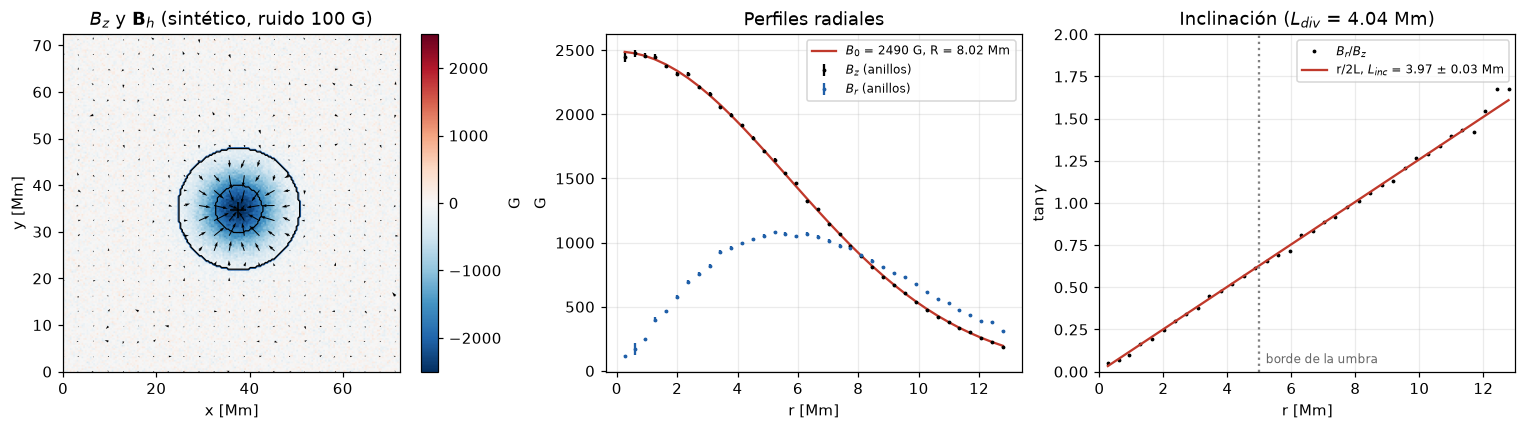

In [6]:
sx, sy, sz = ex.mancha_sintetica(-B0, R, L, n=-1, nx=201, dx=DX, ruido=100.0, semilla=7, centro=(104.2, 96.5))
X, Y = ex.rejilla(sz.shape, DX, (104.2, 96.5)); rmap = np.hypot(X, Y)
mask = np.where(rmap < 5, 1, np.where(rmap < 13, 2, 0))        # umbra de 5 Mm, penumbra hasta 13 Mm
a = pf.ajustar_mancha(sx, sy, sz, DX, mascara=mask)
print(pd.Series({k: v for k, v in a.items() if np.isscalar(v)}).to_string())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), layout='constrained')
im = ax[0].imshow(sz, origin='lower', cmap='RdBu_r', vmin=-B0, vmax=B0, extent=[0, 201 * DX, 0, 201 * DX])
ax[0].contour(mask, levels=[0.5, 1.5], colors=['#1f5fa8', 'k'], linewidths=0.8, extent=[0, 201 * DX, 0, 201 * DX])
q = slice(None, None, 9)
ax[0].quiver((np.arange(201) * DX)[q], (np.arange(201) * DX)[q], sx[q, q], sy[q, q], scale=2.5e4, width=0.003)
ax[0].plot(a['centro'][0] * DX, a['centro'][1] * DX, 'k+', ms=10); ax[0].grid(False)
ax[0].set(title='$B_z$ y $\\mathbf{B}_h$ (sintético, ruido 100 G)', xlabel='x [Mm]', ylabel='y [Mm]'); fig.colorbar(im, ax=ax[0], label='G')
ax[1].errorbar(a['r'], a['Bz'], a['sBz'] / np.sqrt(a['n_px']), fmt='.', c='k', ms=3, label='$B_z$ (anillos)')
ax[1].plot(a['r'], a['B0'] * np.exp(-(a['r'] / a['R']) ** 2), c='#c0392b', label=f"$B_0$ = {a['B0']:.0f} G, R = {a['R']:.2f} Mm")
ax[1].errorbar(a['r'], a['Br'], a['sBr'] / np.sqrt(a['n_px']), fmt='.', c='#1f5fa8', ms=3, label='$B_r$ (anillos)')
ax[1].set(xlabel='r [Mm]', ylabel='G', title='Perfiles radiales'); ax[1].legend(fontsize=8)
ax[2].plot(a['r'], a['Br'] / a['Bz'], 'k.', ms=3, label='$B_r/B_z$')
ax[2].plot(a['r'], a['r'] / (2 * a['L_inc']), c='#c0392b', label=f"r/2L, $L_{{inc}}$ = {a['L_inc']:.2f} ± {a['err_L_inc']:.2f} Mm")
ax[2].axvline(a['r_umbra'], c='0.5', ls=':'); ax[2].text(a['r_umbra'] + 0.2, 0.05, 'borde de la umbra', fontsize=8, c='0.4')
ax[2].set(xlabel='r [Mm]', ylabel='$\\tan\\gamma$', title=f"Inclinación ($L_{{div}}$ = {a['L_div']:.2f} Mm)", ylim=(0, 2), xlim=(0, 13)); ax[2].legend(fontsize=8)
fig.savefig(FIG / '04_ajuste_sintetico.png', dpi=160); plt.show()

## 4. De presiones a $Z_W$ (S5)

Con el nivel 1 de S3 (atmósfera isoterma): $Z_W=H_p\ln(1+\Delta p/p_0)$, $\Delta p=B^2/2\mu_0+C$. Los valores $p_0=1.2\times10^4$ Pa y $H_p=150$ km son de orden de magnitud y se reemplazan por las atmósferas de Maltby cuando esté `atmosferas.py` (todas las funciones aceptan `conversor=`).

Tabla de descomposición para la mancha de referencia: cuánto aporta la presión magnética sola y cuánto cambia la curvatura según $n$.

In [7]:
d = mw.descomponer(B0, R, L, n_lista=(-1, -1.5, -2, np.inf))
filas = [{'modelo': 'presión sola (C = 0)', 'C/Pmag': 0.0, 'Z_W [km]': d['Z_presion'], 'cambio por curvatura [km]': 0.0}]
for tag in ('-1', '-1.5', '-2', 'exp'):
    filas.append({'modelo': f'presión + curvatura, n = {tag}', 'C/Pmag': d[f'C/P_mag[n={tag}]'],
                  'Z_W [km]': d[f'Z[n={tag}]'], 'cambio por curvatura [km]': d[f'dZ_curvatura[n={tag}]']})
print(f"B0 = {B0:.0f} G, R/L = {R / L:.1f}, Pmag = {d['P_mag']:.3g} Pa, Hp = {mw.HP_KM:.0f} km, p0 = {mw.P0_PA:.2g} Pa")
pd.DataFrame(filas).set_index('modelo')

B0 = 2500 G, R/L = 2.0, Pmag = 2.49e+04 Pa, Hp = 150 km, p0 = 1.2e+04 Pa


,C/Pmag,Z_W [km],cambio por curvatura [km]
modelo,,,
presión sola (C = 0),0,168.4,0
"presión + curvatura, n = -1",0.5,212,43.59
"presión + curvatura, n = -1.5",0.1667,184.3,15.98
"presión + curvatura, n = -2",0,168.4,0
"presión + curvatura, n = exp",-0.5,106.7,-61.71


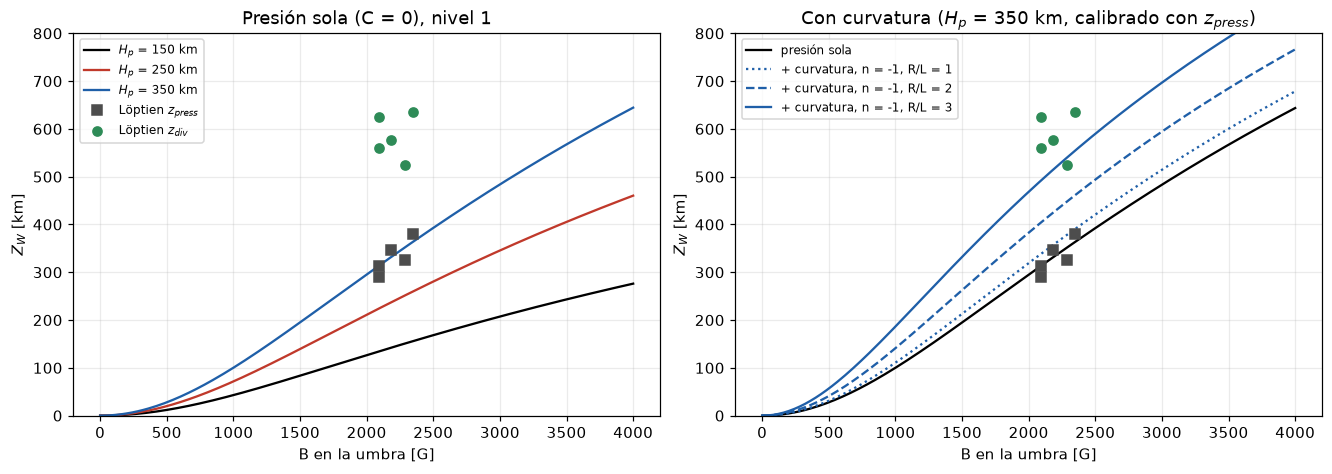

In [8]:
LOPTIEN = pd.DataFrame([('11106', '2010-09-16', 2349, 636, 381), ('11117', '2010-10-27', 2093, 561, 291),
                        ('11117', '2010-10-28', 2090, 625, 313), ('11363', '2011-12-06', 2287, 524, 326),
                        ('11536', '2012-07-31', 2181, 577, 346)], columns=['NOAA', 'fecha', 'B', 'z_div', 'z_press'])
Bg = np.linspace(0, 4000, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), layout='constrained')
for Hp, c in ((150, 'k'), (250, '#c0392b'), (350, '#1f5fa8')):
    ax[0].plot(Bg, mw.Z_W(Bg, Hp=Hp), c=c, label=f'$H_p$ = {Hp} km')
ax[0].plot(LOPTIEN.B, LOPTIEN.z_press, 's', c='0.3', label='Löptien $z_{press}$')
ax[0].plot(LOPTIEN.B, LOPTIEN.z_div, 'o', c='#2e8b57', label='Löptien $z_{div}$')
ax[0].set(xlabel='B en la umbra [G]', ylabel='$Z_W$ [km]', title='Presión sola (C = 0), nivel 1', ylim=(0, 800)); ax[0].legend(fontsize=8)

Hp_med = float(np.median(mw.calibrar_Hp(LOPTIEN.B, LOPTIEN.z_press)))
ax[1].plot(Bg, mw.Z_W(Bg, Hp=Hp_med), 'k', label='presión sola')
for RL, ls in ((1.0, ':'), (2.0, '--'), (3.0, '-')):
    ax[1].plot(Bg, mw.Z_W(Bg, RL, 1.0, -1, Hp=Hp_med), c='#1f5fa8', ls=ls, label=f'+ curvatura, n = -1, R/L = {RL:g}')
ax[1].plot(LOPTIEN.B, LOPTIEN.z_press, 's', c='0.3'); ax[1].plot(LOPTIEN.B, LOPTIEN.z_div, 'o', c='#2e8b57')
ax[1].set(xlabel='B en la umbra [G]', ylabel='$Z_W$ [km]', ylim=(0, 800),
          title=f'Con curvatura ($H_p$ = {Hp_med:.0f} km, calibrado con $z_{{press}}$)'); ax[1].legend(fontsize=8)
fig.savefig(FIG / '04_ZW_vs_B.png', dpi=160); plt.show()

## 5. Calibración con Löptien (S6), parte que no depende de los datos

La diferencia $z_{div}-z_{press}$ es lo que la curvatura tiene que explicar. Con el nivel 1:

1. $H_p$ se calibra por fecha para que $C=0$ reproduzca $z_{press}$ (absorbe en un número la atmósfera real).
2. $C_{req}=p_0\left(e^{z_{div}/H_p}-1\right)-B^2/2\mu_0$.
3. $n=-2/(1+8g)$, con $g=\dfrac{C_{req}/P_{mag}}{(R/L)^2}$.

Los pasos 1 y 2 salen de la tabla de Löptien. El paso 3 necesita $R/L$ de HMI para cada mancha (sección 6); mientras tanto se muestra $n$ para varios $R/L$.

**Ojo:** el $\langle B\rangle$ de Löptien es el promedio de la umbra, no el campo en el eje; el nivel 1 es sensible a $p_0$; y el $H_p$ que sale (324–366 km) es más del doble del valor fotosférico. Además falta confirmar en el artículo qué supone exactamente su $z_{press}$ (qué $B$ usa): aquí se toma como "$C=0$ con $\langle B\rangle$". Estos números son preliminares y no restringen nada hasta tener las atmósferas de Maltby.

In [9]:
filas = []
for _, s in LOPTIEN.iterrows():
    Hp = float(mw.calibrar_Hp(s.B, s.z_press)); pm = float(au.presion_magnetica(s.B))
    c = float(mw.C_requerida(s.B, s.z_div, Hp=Hp))
    fila = {'NOAA': s.NOAA, 'fecha': s.fecha, 'Pmag [Pa]': pm, 'Hp [km]': Hp, 'z_div - z_press [km]': s.z_div - s.z_press,
            'C_req [Pa]': c, 'C_req/Pmag': c / pm, 'R/L si n = -1': np.sqrt(8 * c / pm)}
    for RL in (2, 3, 4, 5):
        fila[f'n si R/L = {RL}'] = float(au.n_desde_C(c, s.B, RL, 1.0))
    filas.append(fila)
cal = pd.DataFrame(filas)
cal

,NOAA,fecha,Pmag [Pa],Hp [km],z_div - z_press [km],C_req [Pa],C_req/Pmag,R/L si n = -1,n si R/L = 2,n si R/L = 3,n si R/L = 4,n si R/L = 5
0,11106,2010-09-16,2.195e+04,366.3,255,3.416e+04,1.556,3.528,-0.4864,-0.8393,-1.125,-1.335
1,11117,2010-10-27,1.743e+04,324.4,270,3.822e+04,2.193,4.188,-0.3713,-0.6781,-0.954,-1.175
2,11117,2010-10-28,1.738e+04,349.6,312,4.235e+04,2.437,4.415,-0.3405,-0.6318,-0.9016,-1.124
3,11363,2011-12-06,2.081e+04,324.1,198,2.763e+04,1.328,3.259,-0.5471,-0.9174,-1.202,-1.404
4,11536,2012-07-31,1.893e+04,365.5,231,2.726e+04,1.44,3.395,-0.5154,-0.8771,-1.163,-1.369


In [10]:
# Sensibilidad a p0 (el supuesto más débil del nivel 1): C_req/Pmag promedio de las 5 fechas
sens = []
for p0 in (0.8e4, 1.2e4, 2e4, 4e4):
    x = [float(mw.C_requerida(s.B, s.z_div, s.z_press, p0=p0) / au.presion_magnetica(s.B)) for _, s in LOPTIEN.iterrows()]
    sens.append({'p0 [Pa]': p0, 'C_req/Pmag medio': np.mean(x), 'mín': np.min(x), 'máx': np.max(x)})
pd.DataFrame(sens).set_index('p0 [Pa]')

,C_req/Pmag medio,mín,máx
p0 [Pa],,,
8000,2.261,1.63,3.155
1.2e+04,1.791,1.328,2.437
2e+04,1.399,1.063,1.861
4e+04,1.094,0.8466,1.429


**Lectura.** $n>0$ o $n<-2$ darían $C\le0$, así que $z_{div}>z_{press}$ obliga a $-2<n<0$: el campo en el eje tiene que caer con la altura de forma más "recta" que $\sqrt{B_0}$ lineal (para $n=-1$, lineal). Siempre hay un $n$ en ese intervalo, pero no todos son creíbles: en la familia el campo del eje se anula a la altura $z=|n|L$, así que un $|n|$ pequeño (lo que sale si el $R/L$ medido es chico) quiere decir que el campo tendría que desaparecer a una fracción de $L$ por encima de la fotosfera. Si eso pasa, el modelo gaussiano autosimilar no alcanza para explicar $z_{div}-z_{press}$ y hay que decirlo. Incluso con $n=-1$ los $R/L\approx3.3$–$4.4$ que hacen falta ponen el cero del campo a $L\approx R/4$ sobre la fotosfera (unos 2 Mm para $R=8$ Mm): ya es el límite de lo creíble. La columna `R/L si n = -1` da el $R/L$ que haría falta con caída lineal.

## 6. Datos reales (`data/processed/`)

Corre si ya están los FITS de 03. Para cada mancha ajusta todos los frames (la dispersión entre frames es la barra de error), calcula la descomposición de $Z_W$ y, para las de Löptien, calibra $n$. Escribe `data/processed/modelo_zw.csv`.

In [11]:
from src import config
CADA = 5            # usa 1 de cada CADA frames (1 = todos)
disponibles = [s for s in config.all_spots() if (config.PROCESSED_DIR / s['id'] / 'cea' / 'Bz').exists()]
if not disponibles:
    print('No hay datos en data/processed/: corre 01 → 02 → 03 (o copia los procesados) y vuelve a correr esta sección.')
filas, series = [], {}
for s in disponibles:
    df = pf.ajustar_serie(s['id'], cada=CADA)
    if df.empty:
        print(s['id'], 'sin frames ajustables'); continue
    series[s['id']] = df
    m, e = df.median(numeric_only=True), df.std(numeric_only=True)
    fila = {'id': s['id'], 'noaa': s['noaa'], 'kind': s['kind'], 'n_frames': len(df)}
    for k in ('B0', 'R', 'L_inc', 'L_div', 'consistencia', 'r_umbra',
              'p_forma', 'rms_gauss', 'exp_inc', 'tan_borde', 'rms_inc'):
        fila[k], fila[f'{k}_std'] = m[k], e[k]
    fila['R_sobre_L'] = m['R'] / m['L_inc']
    d = mw.descomponer(m['B0'], m['R'], m['L_inc'])
    fila.update({k: v for k, v in d.items() if k.startswith(('P_mag', 'Z', 'dZ', 'C/'))})
    # Barras de error: el modelo se evalúa frame por frame y se toma la desviación estándar.
    porframe = pd.DataFrame([mw.descomponer(b, r, l) for b, r, l in zip(df.B0, df.R, df.L_inc)])
    fila['R_sobre_L_std'] = (df.R / df.L_inc).std()
    fila.update({f'{k}_std': porframe[k].std() for k in porframe if k.startswith(('P_mag', 'Z', 'dZ', 'C/'))})
    if s['kind'] == 'loptien':
        fila.update(z_div=s['z_div'], z_press=s['z_press'], B_loptien=s['B'])
        # B de la presión: el <B> umbral de Löptien, el mismo con que él calcula z_press (igual que en la
        # sección 5). R/L sí sale de HMI. Cambiar a m['B0'] es la otra opción; está por decidir con el grupo.
        fila.update({f'cal_{k}': v for k, v in mw.calibrar_n(s['B'], m['R'], m['L_inc'], s['z_div'], s['z_press']).items()})
        fila['cal_n_std'] = np.std([mw.calibrar_n(s['B'], r, l, s['z_div'], s['z_press'])['n']
                                    for r, l in zip(df.R, df.L_inc)], ddof=1)
    filas.append(fila)
if filas:
    modelo = pd.DataFrame(filas)
    modelo.to_csv(config.PROCESSED_DIR / 'modelo_zw.csv', index=False)
    display(modelo)

,id,noaa,kind,n_frames,B0,B0_std,R,R_std,L_inc,L_inc_std,...,dZ_curvatura[n=exp]_std,z_div,z_press,B_loptien,cal_Hp,cal_C,cal_C_sobre_Pmag,cal_g,cal_n,cal_n_std
0,L11106_20100916,11106,loptien,23,2226,30.29,5.251,0.1295,2.817,0.104,...,1.965,636,381,2349,366.3,3.416e+04,1.556,0.4476,-0.4366,0.01226
1,L11117_20101027,11117,loptien,23,1886,66.1,5.906,0.1155,3.159,0.08861,...,2.42,561,291,2093,324.4,3.822e+04,2.193,0.6276,-0.3322,0.01958
2,L11117_20101028,11117,loptien,21,1978,33.52,5.906,0.07174,3.281,0.05754,...,1.254,625,313,2090,349.6,4.235e+04,2.437,0.752,-0.2851,0.006288
3,L11363_20111206,11363,loptien,22,2085,39.01,12.46,0.1368,6.961,0.08836,...,1.053,524,326,2287,324.1,2.763e+04,1.328,0.4147,-0.4633,0.01193
4,L11536_20120731,11536,loptien,23,2002,113.6,4.236,0.1284,3.055,0.1765,...,2.425,577,346,2181,365.5,2.726e+04,1.44,0.7489,-0.2861,0.01943
5,C12526,12526,catalog,44,2568,41.07,9.519,0.1442,4.664,0.1251,...,2.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,C12574,12574,catalog,45,2072,55.01,5.834,0.06392,3.167,0.1371,...,3.445,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,C12600,12600,catalog,46,2417,33.43,7.038,0.08037,3.535,0.1114,...,3.692,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,C12664,12664,catalog,46,2389,54.15,5.661,0.07163,2.979,0.1047,...,3.539,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,C12670,12670,catalog,46,2622,42.75,8.226,0.1044,4.116,0.06895,...,1.865,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
if filas and 'cal_n' in modelo:
    lop = modelo[modelo.kind == 'loptien']
    n_cal, Hp_cal = lop['cal_n'].median(), lop['cal_Hp'].median()
    print(f'n calibrado (mediana de {len(lop)} fechas) = {n_cal:.2f}   rango [{lop.cal_n.min():.2f}, {lop.cal_n.max():.2f}]   Hp = {Hp_cal:.0f} km')
    modelo['Z_pred_presion'] = mw.Z_W(modelo.B0, Hp=Hp_cal)
    modelo['Z_pred_curvatura'] = [mw.Z_W(b, r, l, n_cal, Hp=Hp_cal) for b, r, l in zip(modelo.B0, modelo.R, modelo.L_inc)]
    # Error de la predicción: dispersión entre frames (no incluye el error de n ni de la atmósfera).
    modelo['Z_pred_presion_std'] = [mw.Z_W(series[i].B0, Hp=Hp_cal).std() for i in modelo.id]
    modelo['Z_pred_curvatura_std'] = [np.std([mw.Z_W(b, r, l, n_cal, Hp=Hp_cal) for b, r, l in
                                              zip(series[i].B0, series[i].R, series[i].L_inc)], ddof=1) for i in modelo.id]
    display(modelo[['id', 'kind', 'B0', 'R_sobre_L', 'Z_pred_presion', 'Z_pred_curvatura', 'z_press', 'z_div']])
    modelo.to_csv(config.PROCESSED_DIR / 'modelo_zw.csv', index=False)

n calibrado (mediana de 5 fechas) = -0.33   rango [-0.46, -0.29]   Hp = 350 km


,id,kind,B0,R_sobre_L,Z_pred_presion,Z_pred_curvatura,z_press,z_div
0,L11106_20100916,loptien,2226,1.864,339.7,639.3,381,636
1,L11117_20101027,loptien,1886,1.869,272.3,545.8,291,561
2,L11117_20101028,loptien,1978,1.8,290.7,558,313,625
3,L11363_20111206,loptien,2085,1.789,311.9,585.4,326,524
4,L11536_20120731,loptien,2002,1.387,295.6,478.8,346,577
5,C12526,catalog,2568,2.041,405.1,764.2,NaN,NaN
6,C12574,catalog,2072,1.842,309.4,592.9,NaN,NaN
7,C12600,catalog,2417,1.991,376.6,716,NaN,NaN
8,C12664,catalog,2389,1.901,371.3,689.3,NaN,NaN
9,C12670,catalog,2622,1.998,415.1,767.7,NaN,NaN


## 7. Perfiles y ajustes por mancha (entregable de S4/S5)

Una figura por mancha con el frame central: mapa $B_z$ con la máscara de 03, perfil $B_z(r)$ con la gaussiana, $\tan\gamma(r)$ con las rectas $r/2L_{inc}$ y $r/2L_{div}$, y la serie de $B_0$, $R$, $L$ por frame. Se guardan en `docs/figuras/04_perfiles_<id>.png`.

Tres preguntas al modelo: ¿$B_z(r)$ es gaussiano ($p=2$)?, ¿$\tan\gamma$ es lineal en la umbra ($q=1$)?, ¿$L_{inc}\approx L_{div}$?

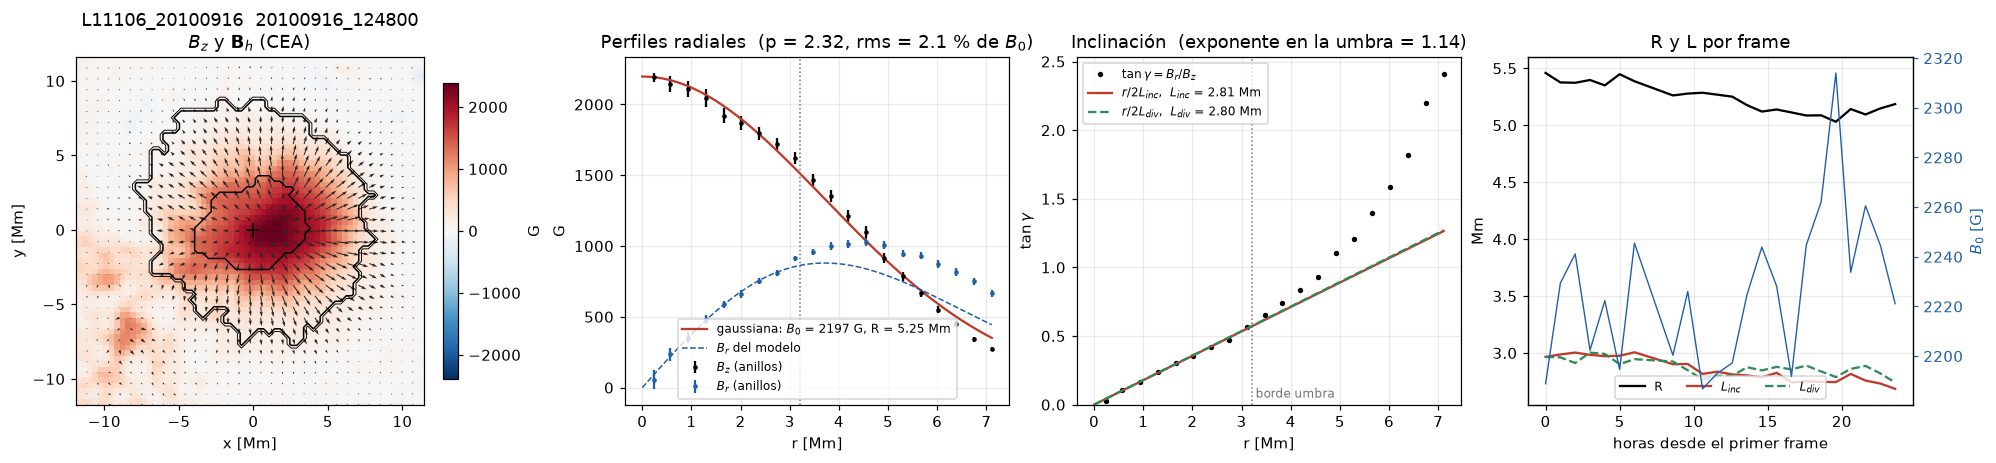

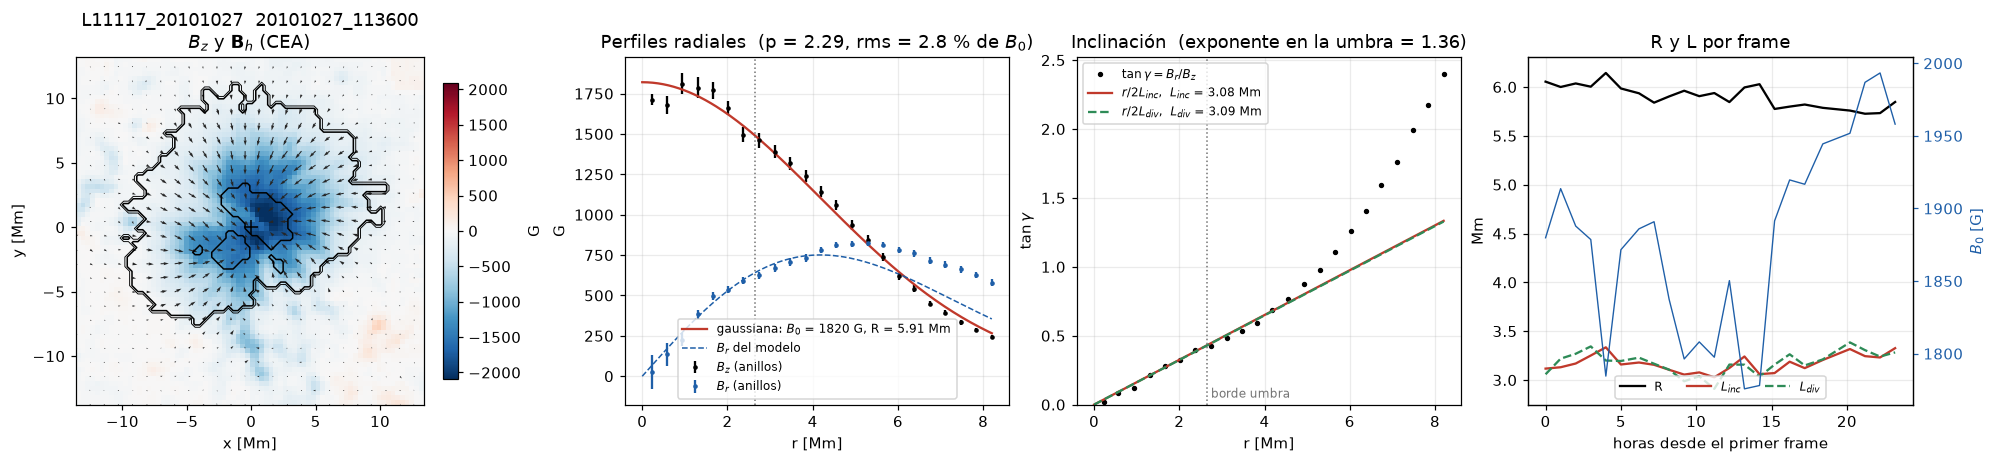

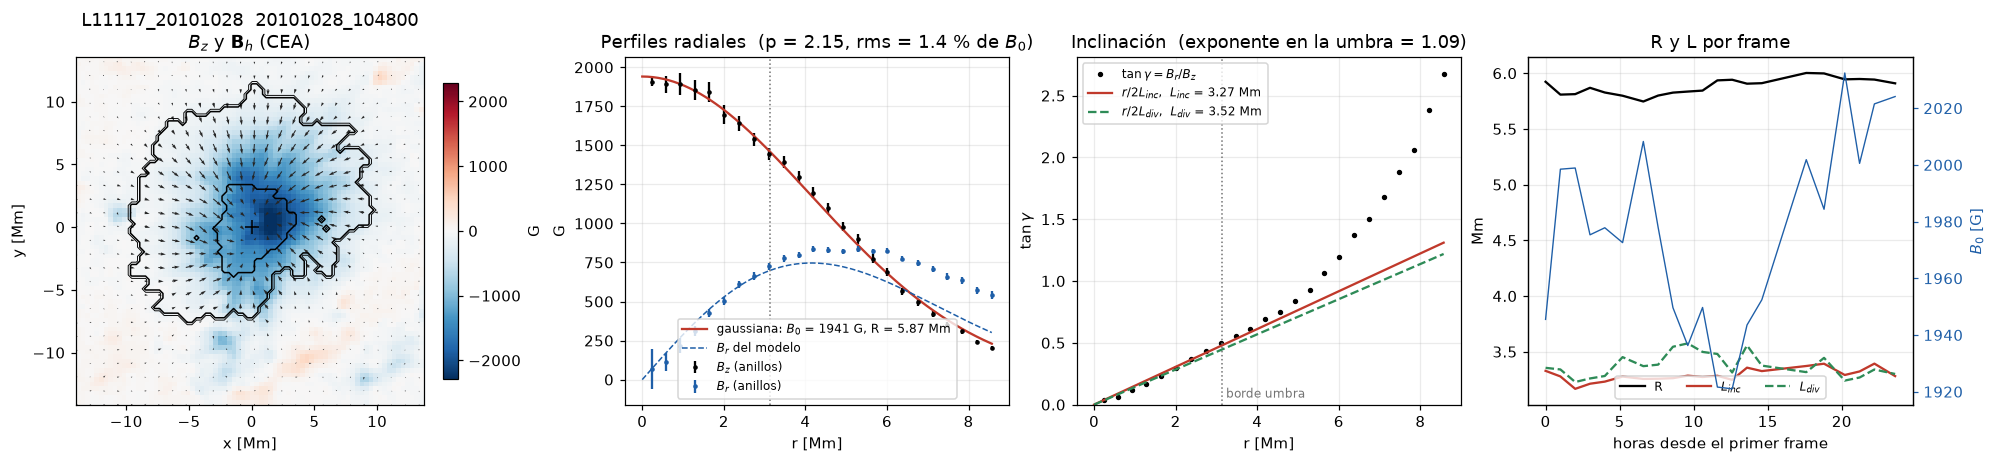

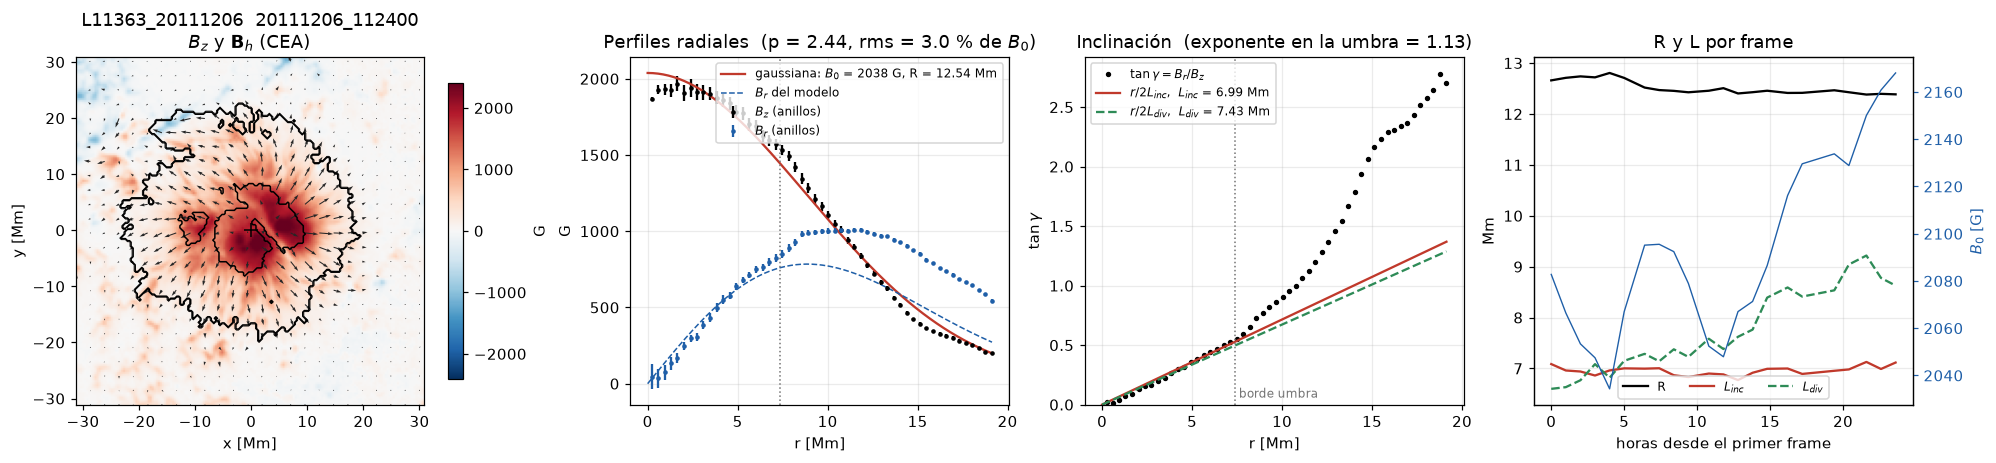

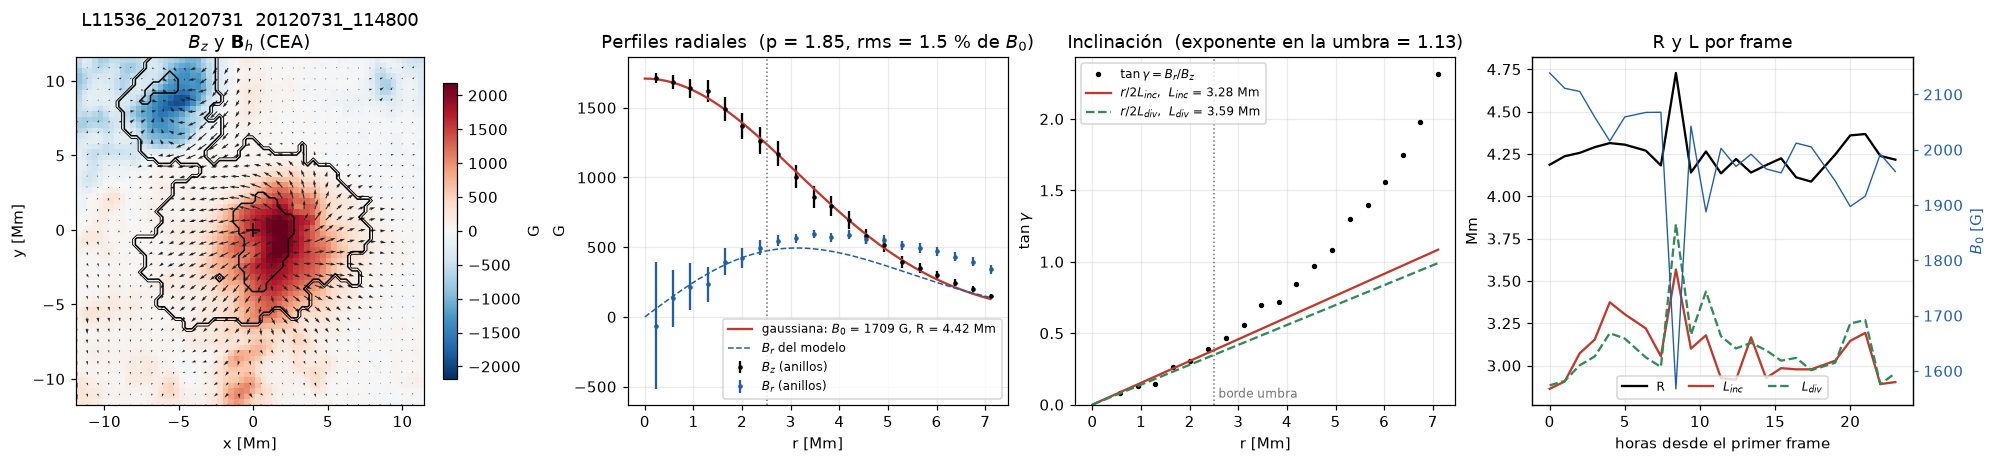

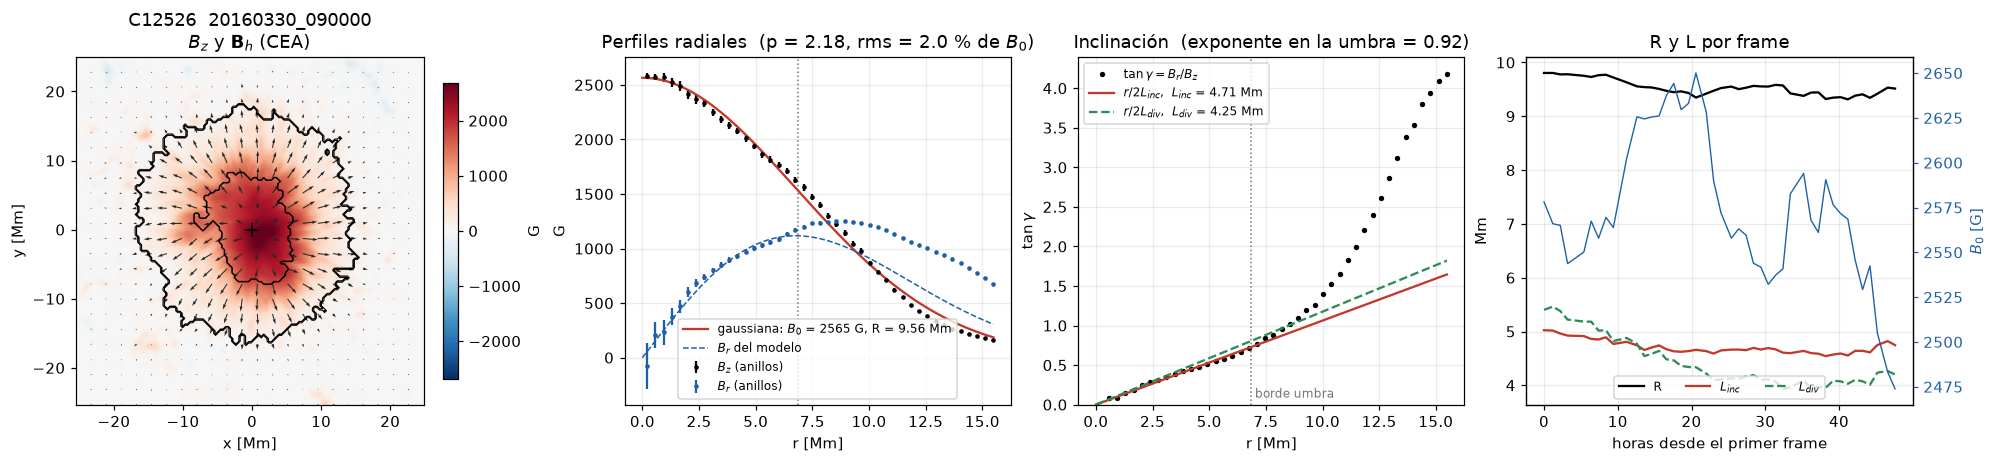

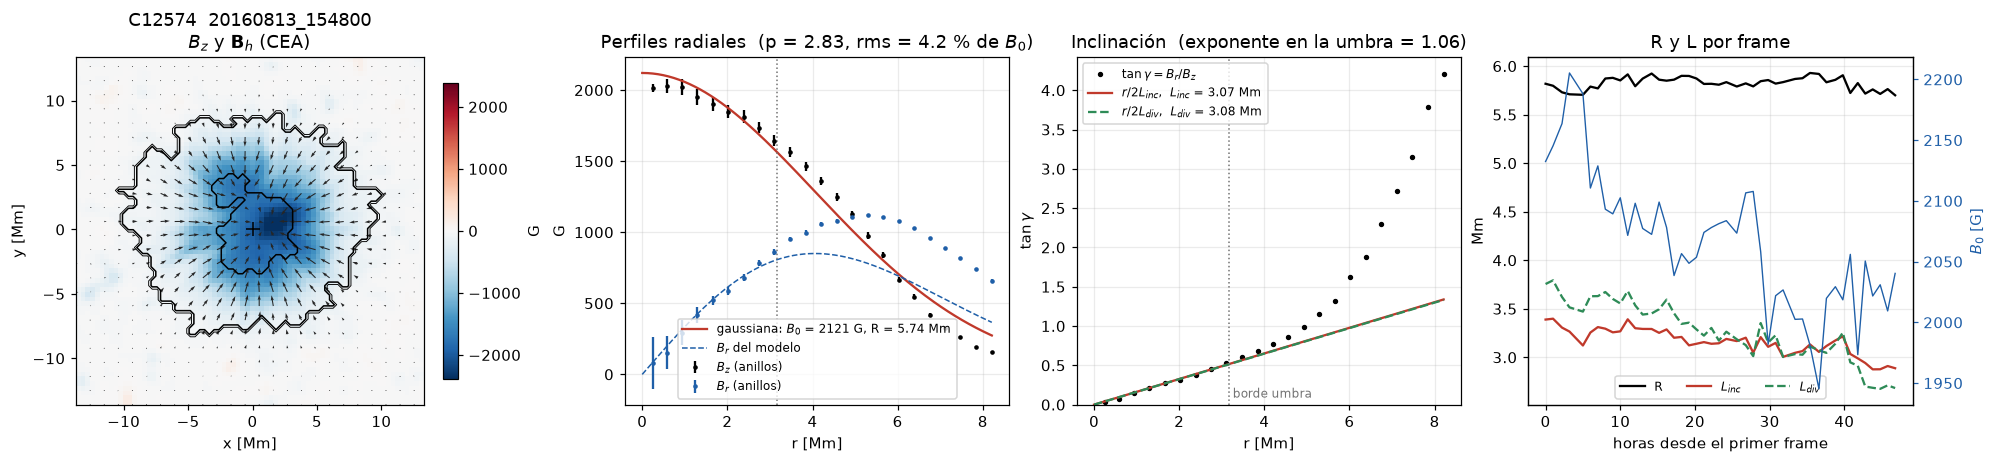

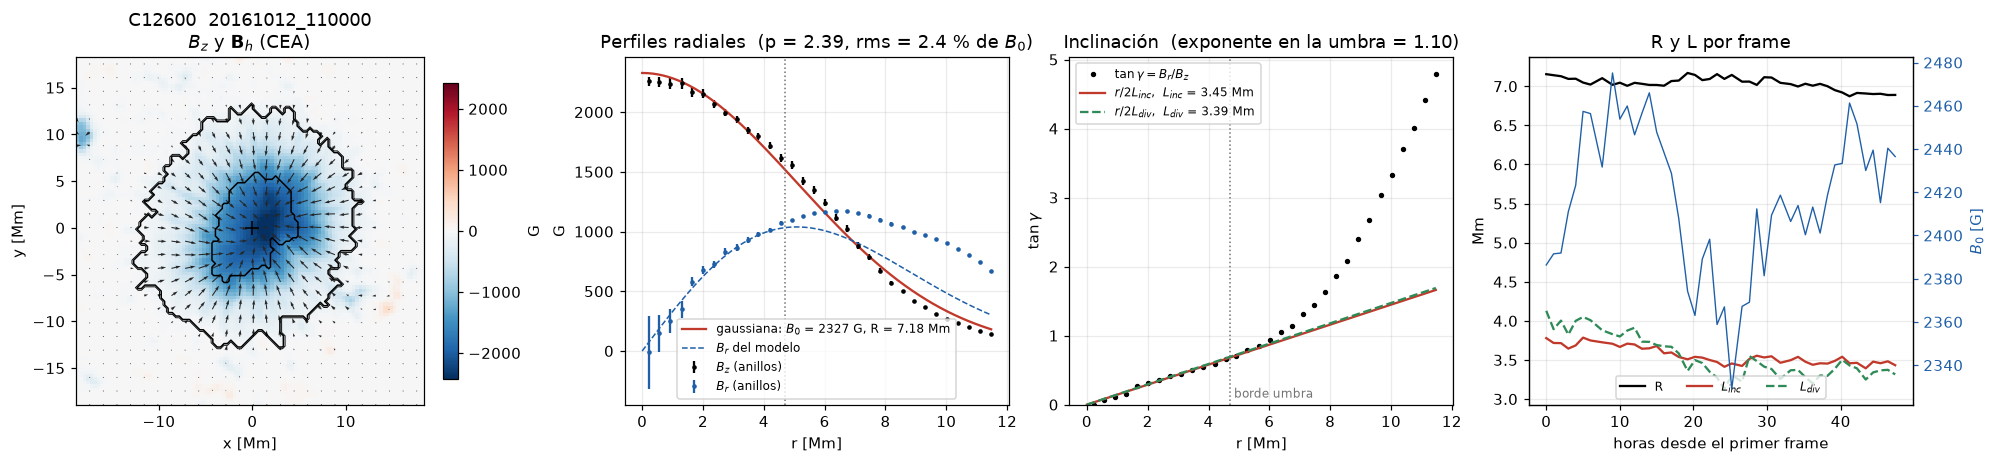

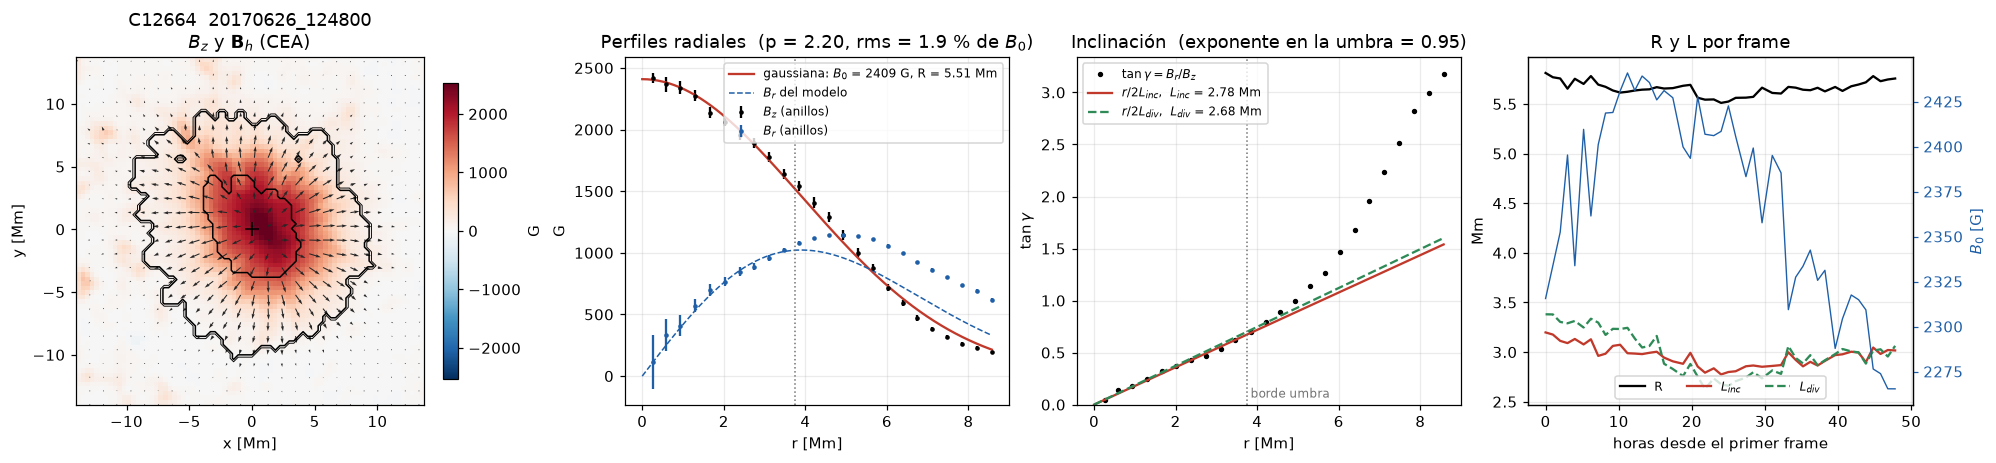

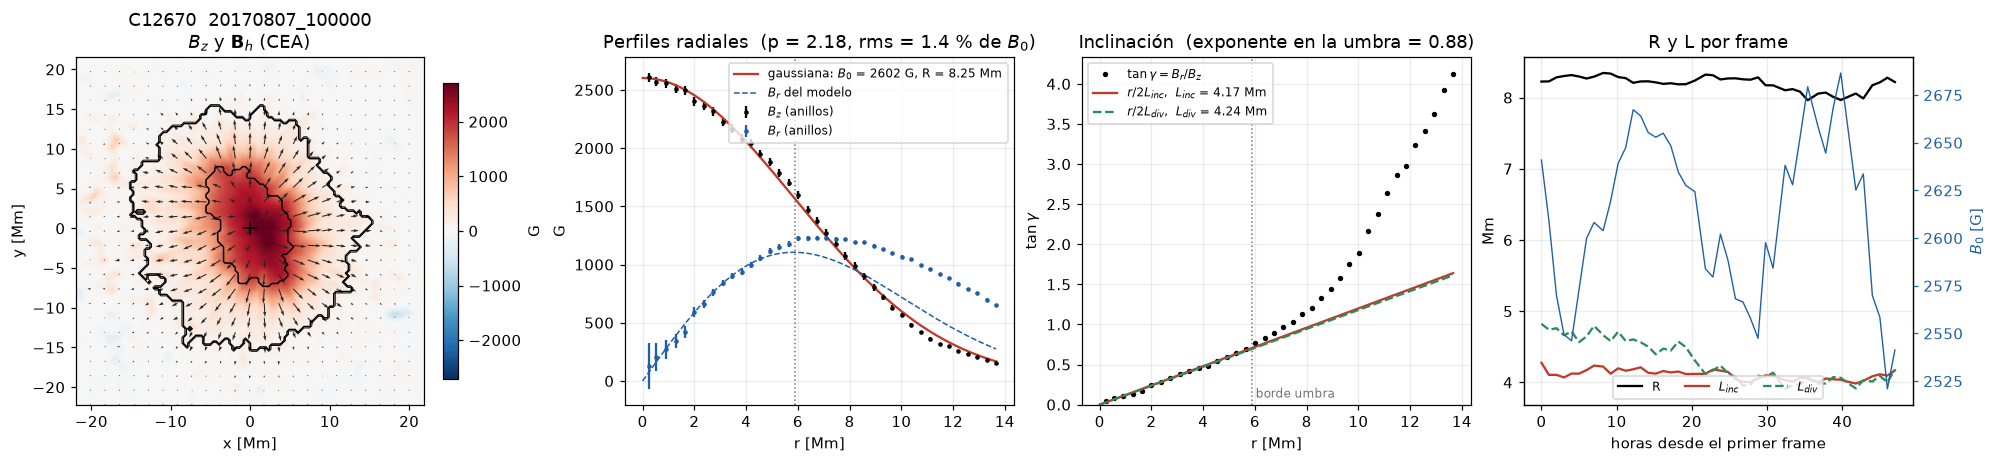

In [13]:
from src import figuras_simulacion as fs
for sid, df in series.items():
    fig, _ = fs.figura_mancha(sid, df)
    fig.savefig(FIG / f'04_perfiles_{sid}.png', dpi=130); plt.show()

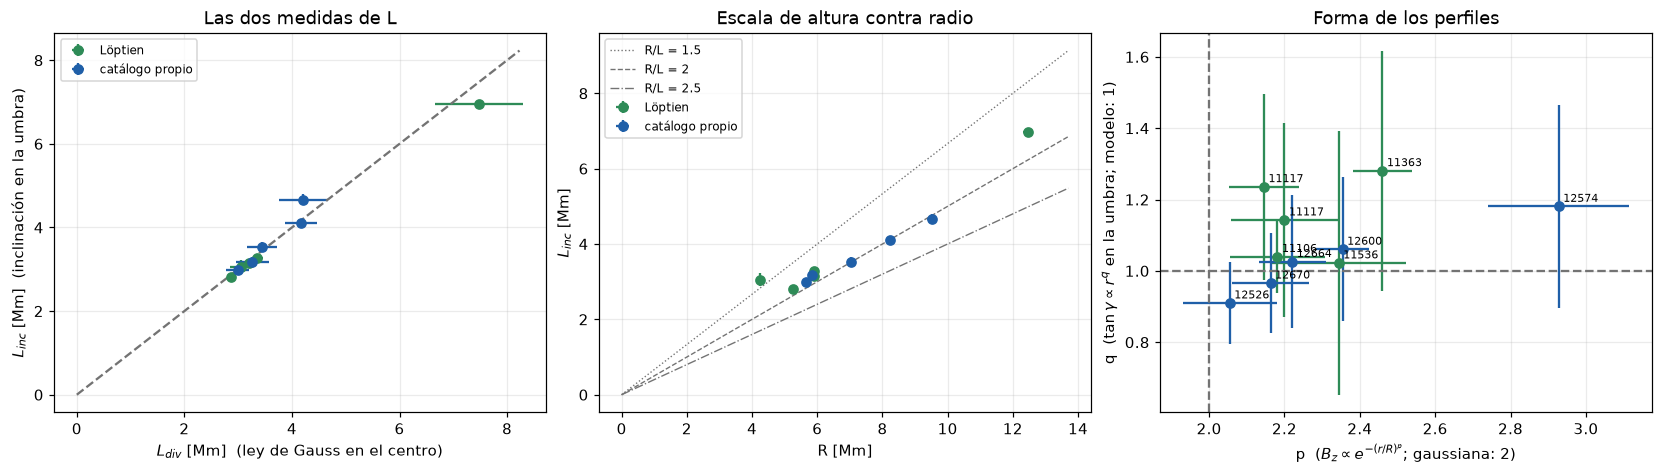

,id,B0,R,L_inc,L_div,consistencia,R_sobre_L,p_forma,rms_gauss,exp_inc,rms_inc
0,L11106_20100916,2226,5.251,2.817,2.876,0.9919,1.864,2.181,0.01818,1.04,0.00913
1,L11117_20101027,1886,5.906,3.159,3.195,0.9965,1.869,2.2,0.01857,1.143,0.01447
2,L11117_20101028,1978,5.906,3.281,3.356,0.9813,1.8,2.145,0.01613,1.236,0.01368
3,L11363_20111206,2085,12.46,6.961,7.483,0.9204,1.789,2.46,0.03294,1.281,0.02742
4,L11536_20120731,2002,4.236,3.055,3.054,0.9929,1.387,2.344,0.02339,1.022,0.0277
5,C12526,2568,9.519,4.664,4.21,1.12,2.041,2.055,0.01928,0.9099,0.02371
6,C12574,2072,5.834,3.167,3.264,0.9755,1.842,2.928,0.04648,1.181,0.0266
7,C12600,2417,7.038,3.535,3.446,1.02,1.991,2.354,0.0229,1.06,0.01824
8,C12664,2389,5.661,2.979,2.989,0.9949,1.901,2.221,0.01826,1.026,0.01693
9,C12670,2622,8.226,4.116,4.175,0.9896,1.998,2.163,0.0162,0.9657,0.01365


        consistencia  R_sobre_L  p_forma  exp_inc
median        0.9924      1.867     2.21     1.05
min           0.9204      1.387    2.055   0.9099
max             1.12      2.041    2.928    1.281


In [14]:
if filas:
    fig = fs.figura_resumen(modelo)
    fig.savefig(FIG / '04_resumen_manchas.png', dpi=150); plt.show()
    cols = ['id', 'B0', 'R', 'L_inc', 'L_div', 'consistencia', 'R_sobre_L', 'p_forma', 'rms_gauss', 'exp_inc', 'rms_inc']
    display(modelo[cols])
    print(modelo[['consistencia', 'R_sobre_L', 'p_forma', 'exp_inc']].agg(['median', 'min', 'max']).to_string())

## 8. La extensión a 3D sobre los mapas reales

Lo mismo que la sección 2, pero partiendo del mapa de HMI (frame central, recortado a $2\,r_{mancha}$ alrededor del centro). $C$ se integra hasta el borde de la penumbra y se normaliza con $B_0^2/2\mu_0$ del ajuste. La columna `B_h modelo/obs` compara el $\mathbf B_h$ que predice la expansión autosimilar en $z=0$ con el observado (cociente de rms dentro de la umbra, y fuera de ella hasta el borde de la mancha).

In [15]:
from scipy.ndimage import gaussian_filter
zc = np.linspace(0, 1.2, 7)
filas3d = []
for s in disponibles:
    sellos = pf.listar_frames(s['id']); fr = pf.cargar_frame(s['id'], sellos[len(sellos) // 2])
    dx = fr['dx']
    a = pf.ajustar_mancha(fr['Bx'], fr['By'], fr['Bz'], dx, mascara=fr['mask'], conf=fr['conf_disambig'])
    xc, yc = (int(round(v)) for v in a['centro']); rs = a['r'][-1]; h = int(2 * rs / dx)
    ny, nx = fr['Bz'].shape; h = min(h, xc, yc, nx - 1 - xc, ny - 1 - yc)
    rec = lambda m: a['polaridad'] * np.nan_to_num(m[yc - h:yc + h + 1, xc - h:xc + h + 1])
    bx, by, bz = rec(fr['Bx']), rec(fr['By']), rec(fr['Bz'])
    pm = au.presion_magnetica(a['B0']); kw = dict(r_max=rs)
    fila = {'id': s['id'], 'R/L': a['R'] / a['L_inc']}
    cx, cy, _ = ex.capas_iguales(bx, by, bz, len(zc))
    fila['C/Pmag capas+Gauss'] = ex.integral_curvatura(cx, cy, ex.integrar_gauss(cx, cy, bz, dx, zc), dx, zc, **kw)[0] / pm
    px, py, pz, dpx, dpy = ex.campo_potencial(bz, dx, zc, relleno=300)
    fila['C/Pmag potencial'] = ex.integral_curvatura(px, py, pz, dx, dBx_dz=dpx, dBy_dz=dpy, **kw)[0] / pm
    bzs = gaussian_filter(bz, 2.0)
    for n, tag in ((-1, 'n=-1'), (np.inf, 'n=inf')):
        ax_, ay_, az_ = ex.autosimilar_desde_mapa(bzs, dx, zc, a['L_inc'], n)
        fila[f'C/Pmag autosimilar {tag}'] = ex.integral_curvatura(ax_, ay_, az_, dx, zc, **kw)[0] / pm
        fila[f'cerrada {tag}'] = au.C(a['B0'], a['R'], a['L_inc'], n) / pm
    X, Y = ex.rejilla(bz.shape, dx); rr = np.hypot(X, Y)
    bh_obs, bh_mod = np.hypot(bx, by), np.hypot(ax_[0], ay_[0])
    rms = lambda v, sel: np.sqrt(np.mean(v[sel] ** 2))
    um, pe = rr < a['r_umbra'], (rr >= a['r_umbra']) & (rr < rs)
    fila['B_h modelo/obs umbra'] = rms(bh_mod, um) / rms(bh_obs, um)
    fila['B_h modelo/obs penumbra'] = rms(bh_mod, pe) / rms(bh_obs, pe)
    filas3d.append(fila)
ext3d = pd.DataFrame(filas3d).set_index('id')
if len(ext3d):
    ext3d.to_csv(config.PROCESSED_DIR / 'extension_3d.csv')
ext3d

,R/L,C/Pmag capas+Gauss,C/Pmag potencial,C/Pmag autosimilar n=-1,cerrada n=-1,C/Pmag autosimilar n=inf,cerrada n=inf,B_h modelo/obs umbra,B_h modelo/obs penumbra
id,,,,,,,,,
L11106_20100916,1.867,-2.469e-15,-1.023,0.3884,0.4358,-0.4612,-0.4358,0.9122,0.7545
L11117_20101027,1.923,-2.565e-15,-0.7935,0.414,0.4624,-0.496,-0.4624,0.8355,0.7869
L11117_20101028,1.794,-2.485e-15,-0.8635,0.3687,0.4024,-0.4353,-0.4024,0.854,0.7615
L11363_20111206,1.795,-5.927e-15,-0.8641,0.4018,0.4026,-0.4489,-0.4026,0.868,0.6397
L11536_20120731,1.348,-1.573e-15,-1.024,0.2497,0.2272,-0.2964,-0.2272,0.4156,0.5759
C12526,2.031,-4.69e-15,-0.9772,0.5118,0.5159,-0.5351,-0.5159,0.9362,0.7158
C12574,1.87,-2.966e-15,-0.9526,0.4179,0.4371,-0.4446,-0.4371,0.8556,0.6716
C12600,2.081,-3.679e-15,-0.9565,0.5383,0.5412,-0.559,-0.5412,0.9107,0.7071
C12664,1.98,-2.558e-15,-0.8983,0.4638,0.49,-0.5096,-0.49,0.8915,0.7888
